In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

#### DATA COLLECTION


In [22]:
df = pd.read_csv('winequality-red.csv', sep=';')

In [23]:
#first five rows
df.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [24]:
#checking the missing values
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

#### DATA ANALYSIS OF THE DATASET

In [25]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


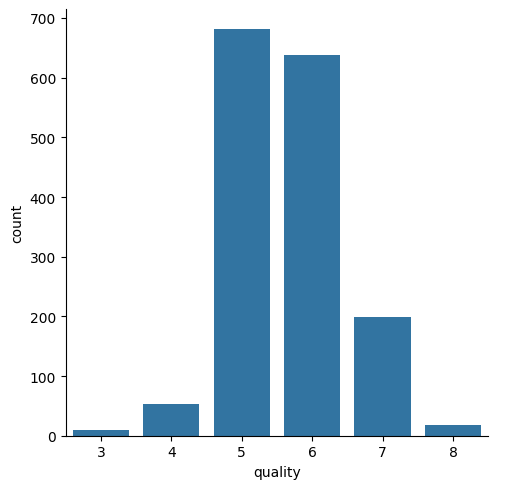

In [26]:
#checking of values for the each quality
sns.catplot(x = 'quality',data=df,kind='count')

In [27]:
df['quality'].unique()

array([5, 6, 7, 4, 8, 3], dtype=int64)

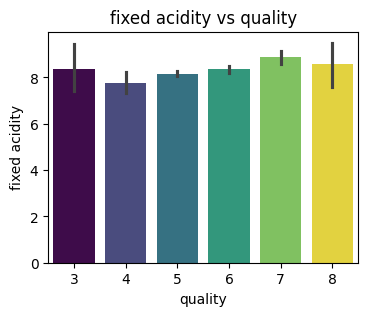

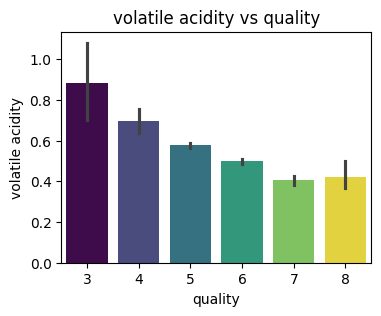

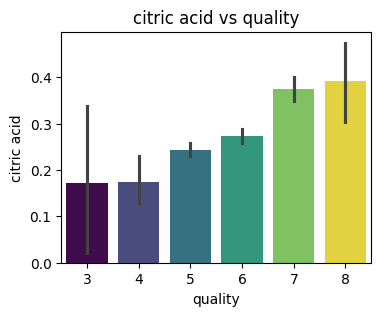

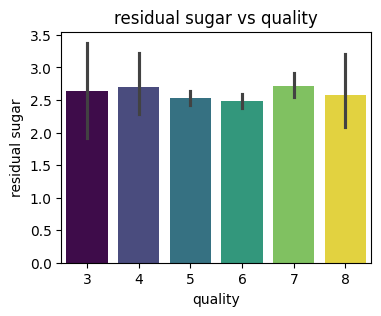

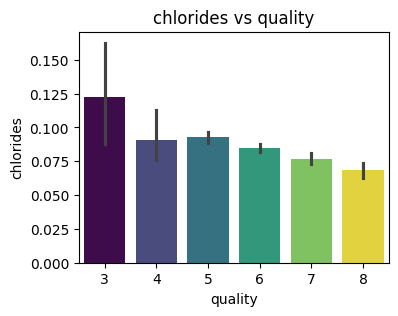

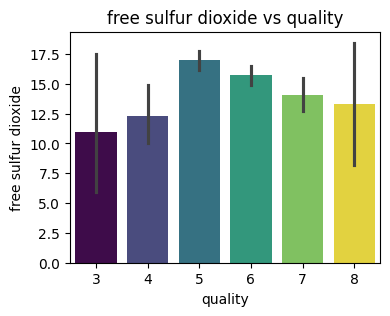

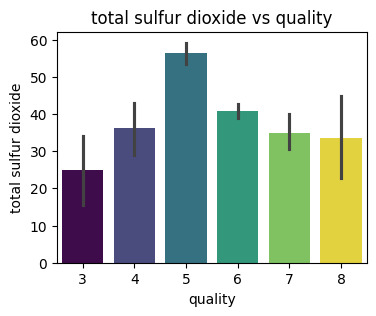

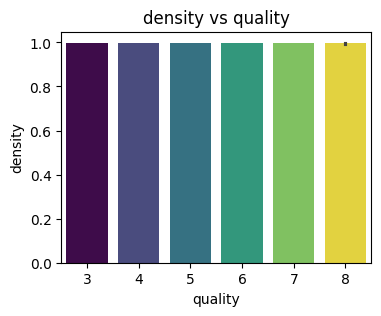

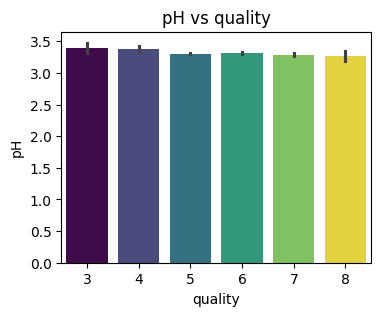

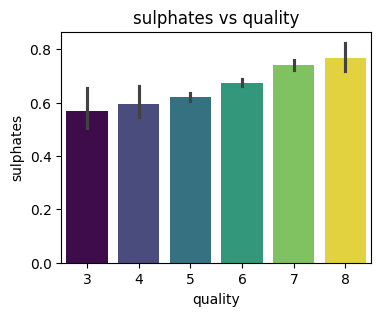

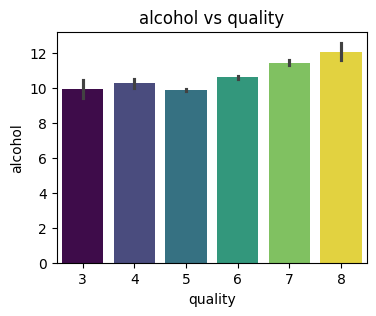

In [28]:
features = df.columns.drop('quality')
for col in features:
    plt.figure(figsize=(4,3))
    sns.barplot(x='quality',y= col,data = df, hue="quality",palette="viridis",legend=False )  
    plt.title(col + " vs quality")      
    plt.show()

### correlation
###### 1.positve Correlation
###### 2.Negative Correlation


In [29]:
correlation = df.corr()

<Axes: >

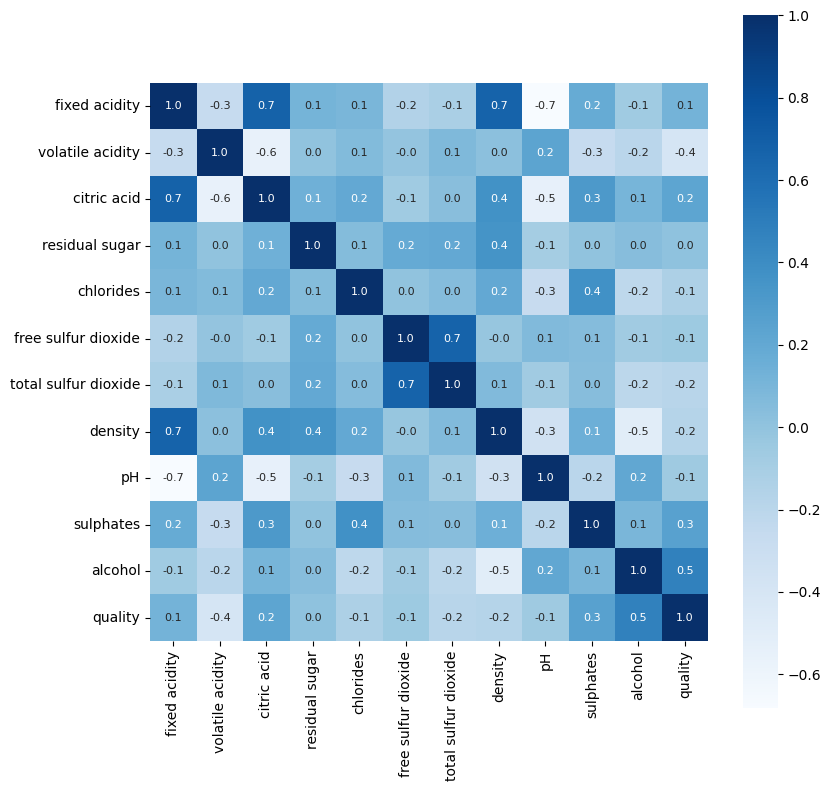

In [30]:
plt.figure(figsize=(9,9))
sns.heatmap(correlation,cbar=True,square = True,fmt= '.1f',annot = True,annot_kws={'size':8},cmap='Blues')

#### DATA PREPROCESSING

In [31]:
x =  df.drop(['quality'],axis = 1)
y = df['quality'].apply(lambda y_value : 1 if y_value>=7 else 0) # label encoding

In [32]:
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state = 32)

#### Model Training

In [33]:
model = RandomForestClassifier()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
print('accuracy: ',accuracy_score(y_test,y_pred))

accuracy:  0.903125


#### Building a Predictive System

In [36]:
input_data = (7.4,0.59,0.08,4.4,0.086,6,29,0.9974,3.38,0.5,9)
input_data_numpy_array = np.asarray(input_data)
# reshape the input array
reshaped_array = input_data_numpy_array.reshape(1,-1)
prediction = model.predict(reshaped_array)
if prediction[0] == 1:
    print('GOOD QUALITY WINE')
else:
    print('BAD Quality Wine')

BAD Quality Wine
